# 📓 Mediana

> **Meu Caderno Digital · Estatística e Probabilidade para IA e Dados**
> Módulo 01 · Estatística Descritiva › Medidas de Posição › Aula 02


### Objetivo da aula:

1. Definir a mediana (com `n` ímpar e par) e explicar a intuição do **ponto 50/50**.
2. Calculá-la **na mão** (dados brutos, agrupados e ponderados) e implementá-la **do zero**, inclusive com *seleção* em tempo linear.
3. Explicar por que ela é **robusta** (ponto de ruptura de 50%) e por que minimiza o **erro absoluto**.
4. Usar a diferença **média − mediana** como diagnóstico de assimetria e saber **o preço da robustez** (eficiência estatística).
5. Reconhecer as armadilhas: mediana de medianas, não aditividade, NaN, empates, dados ordinais e distribuições bimodais.
6. Aplicar a mediana em **Análise de Dados, Ciência de Dados, ML, DL e Engenharia**, incluindo o **filtro de Hampel** para telemetria de sensores.

### 🗺️ Roteiro da aula

| Ato | Seções |
|---|---|
| **I · Por quê** | 1. O problema · 2. A intuição |
| **II · O quê** | 3. Definição formal · 4. Propriedades e relações |
| **III · Como** | 5. Na mão · 6. Em Python · 7. Visualizando |
| **IV · Cuidado** | 8. Armadilhas e limites |
| **V · Onde se aplica** | 9. No trabalho, por área · 10. Mini-caso |
| **VI · Fixar** | 11. Entrevista e exercícios · 12. Resumo e ponte |

> **Legenda dos blocos:** 🧠 Intuição · ⚠️ Armadilha · 🏭 No trabalho · 🎯 Entrevista

In [1]:
import heapq
import math
import statistics
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (9, 4.2), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
COR = {"media": "#d1495b", "mediana": "#00798c", "ponderada": "#edae49", "base": "#30638e"}
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# O dataset fica em data/, dois níveis acima deste notebook
df = pd.read_csv("../../data/dataset_estatistica.csv")
print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")

Dataset carregado: 200 linhas x 7 colunas


---
# ATO I · POR QUÊ
## 1 · O problema: a renda típica do bar

Na aula anterior vimos que a média tem **ponto de ruptura zero**: um único valor extremo pode levá-la a qualquer lugar. Agora vamos ver isso acontecer em uma situação do dia a dia.

Numa noite tranquila, um bar tem 9 clientes. Você anota a renda mensal de cada um:

In [2]:
bar = np.array([2800, 3000, 3100, 3300, 3500, 3600, 3800, 4000, 4200])
com_empresario = np.append(bar, 2_000_000)      # entra um empresário com renda de R$ 2.000.000

for nome, dados in [("9 clientes", bar), ("com o empresário", com_empresario)]:
    print(f"{nome:<18} média = {np.mean(dados):>10.2f} | mediana = {np.median(dados):>8.2f}")

9 clientes         média =    3477.78 | mediana =  3500.00
com o empresário   média =  203130.00 | mediana =  3550.00


Ninguém no bar ficou mais rico. Os 9 clientes continuam com as mesmas rendas, e mesmo assim a **renda média do bar** saltou de cerca de R$ 3,5 mil para mais de R$ 200 mil. Quem divulgar "a renda média do bar é R$ 203 mil" estará tecnicamente correto e completamente enganoso.

A **mediana** quase não se mexeu. Isso levanta duas perguntas que vão guiar a aula:

1. **O que significa um valor "típico"?** Será que a soma dos valores é a melhor forma de descobri-lo?
2. **Existe uma medida que ignore a magnitude dos extremos e olhe só para a posição?**

---
## 2 · A intuição: o valor do meio da fila

> 🧠 **Intuição 1 · A fila.** Ordene todos os valores do menor para o maior e coloque-os em fila. A mediana é **quem está no meio**: metade das pessoas fica antes, metade fica depois.

> 🧠 **Intuição 2 · Democracia vs. plutocracia.** Na média, quem tem mais **valor** tem mais influência (plutocracia). Na mediana, cada observação tem **um voto**, e só a **ordem** importa. O empresário vale um voto, como todo mundo. É a ideia do "eleitor mediano" da ciência política.

Veja a fila de 9 valores (com um valor alto, o 55) e o mesmo conceito na curva de proporção acumulada (ECDF), onde a mediana é o ponto em que a curva cruza **50%**:

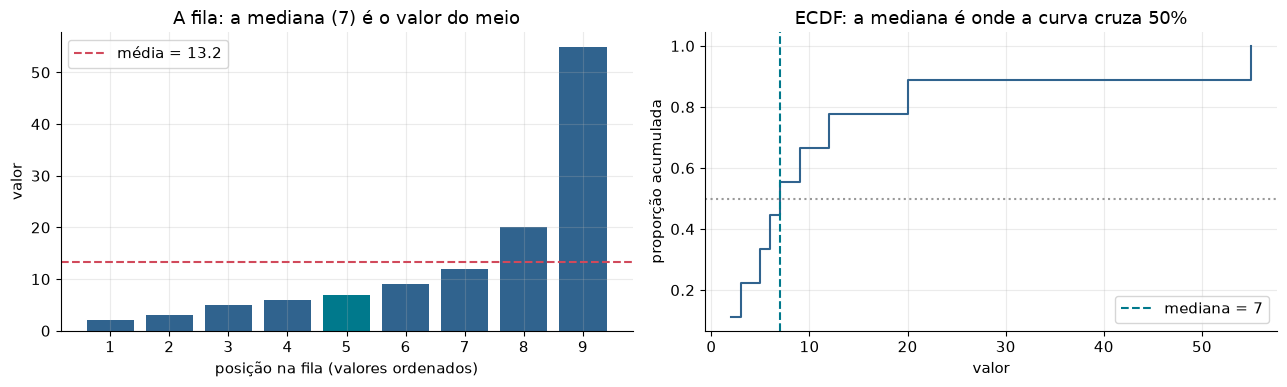

In [3]:
x = np.array([2, 3, 5, 6, 7, 9, 12, 20, 55])
xs = np.sort(x); n = len(xs); m = np.median(xs)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
cores = [COR["mediana"] if v == m else COR["base"] for v in xs]
axs[0].bar(range(1, n + 1), xs, color=cores)
axs[0].axhline(xs.mean(), color=COR["media"], ls="--", label=f"média = {xs.mean():.1f}")
axs[0].set_xticks(range(1, n + 1)); axs[0].set_xlabel("posição na fila (valores ordenados)"); axs[0].set_ylabel("valor")
axs[0].set_title(f"A fila: a mediana ({m:.0f}) é o valor do meio"); axs[0].legend(loc="upper left")

axs[1].step(xs, np.arange(1, n + 1) / n, where="post", color=COR["base"])
axs[1].axhline(0.5, color="#999999", ls=":")
axs[1].axvline(m, color=COR["mediana"], ls="--", label=f"mediana = {m:.0f}")
axs[1].set_xlabel("valor"); axs[1].set_ylabel("proporção acumulada")
axs[1].set_title("ECDF: a mediana é onde a curva cruza 50%"); axs[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

> 🧠 **Intuição 3 · Onde instalar o depósito.** Cinco cidades ficam ao longo de uma estrada, nos quilômetros 0, 10, 12, 30 e 100. Onde instalar **um** depósito para minimizar a **distância total** percorrida? Intuitivamente, perto do "meio" das cidades, não puxado pela cidade distante. A mediana é a resposta exata:

In [4]:
km = np.array([0, 10, 12, 30, 100])
for nome, local in [("mediana", np.median(km)), ("média", km.mean())]:
    print(f"depósito no km {local:>5.1f} ({nome:<7}) -> distância total = {np.abs(km - local).sum():6.1f} km")

depósito no km  12.0 (mediana) -> distância total =  120.0 km
depósito no km  30.4 (média  ) -> distância total =  139.2 km


A mediana **minimiza a soma das distâncias absolutas**, como a média minimiza a soma dos quadrados (Aula 01, propriedade P2). Vamos provar isso numericamente na seção 4.

---
# ATO II · O QUÊ
## 3 · Definição formal

**Estatísticas de ordem.** Dados $n$ valores, ordene-os do menor para o maior e chame o resultado de $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$. O índice entre parênteses indica a **posição** na ordenação.

**Mediana amostral.**

$$\tilde{x} = \begin{cases} x_{\left(\frac{n+1}{2}\right)}, & n \text{ ímpar} \\[6pt] \dfrac{x_{\left(\frac{n}{2}\right)} + x_{\left(\frac{n}{2}+1\right)}}{2}, & n \text{ par} \end{cases}$$

**Mediana populacional.** É o valor $m$ que deixa pelo menos 50% da probabilidade de cada lado:

$$P(X \le m) \ge \tfrac{1}{2} \quad \text{e} \quad P(X \ge m) \ge \tfrac{1}{2} \qquad \Big(\text{em variáveis contínuas: } F(m) = \tfrac{1}{2}\Big)$$

| Símbolo | Nome | O que é |
|---|---|---|
| $x_{(k)}$ | $k$-ésima estatística de ordem | o $k$-ésimo menor valor da amostra |
| $\tilde{x}$ | mediana amostral | estimativa calculada dos dados |
| $m$ | mediana populacional | parâmetro, em geral desconhecido |
| $F$ | função de distribuição acumulada (CDF) | $F(x) = P(X \le x)$ |

### Quatro conexões que valem ouro

1. **Quantil 0,5.** A mediana é o **percentil 50**, o **segundo quartil** $Q_2$ e o quantil $Q(0{,}5) = F^{-1}(0{,}5)$. Toda a família de quantis nasce dela.
2. **Só depende da ordem.** Os valores entram apenas por sua posição relativa. Por isso a mediana é invariante a transformações crescentes (seção 4, P2).
3. **Dados agrupados.** Quando só temos as frequências por classe, usamos interpolação linear dentro da classe mediana:

$$\tilde{x} = L + \frac{\frac{n}{2} - F_{\text{ant}}}{f_{\text{med}}}\, h$$

em que $L$ é o limite inferior da classe mediana, $F_{\text{ant}}$ a frequência acumulada **antes** dela, $f_{\text{med}}$ sua frequência e $h$ sua amplitude.

4. **Mediana ponderada.** É o menor valor $x_{(k)}$ cujo peso acumulado atinge **50%** do peso total. É a ponte com a Aula 01: assim como a média, a mediana também aceita pesos.

---
## 4 · Propriedades e relações

Como na aula anterior, vamos **verificar cada propriedade com código**.

### P1 · A mediana minimiza o erro absoluto (e, com $n$ par, o mínimo é um intervalo)

$$\tilde{x} \in \arg\min_{c} \sum_{i=1}^{n}|x_i - c|$$

Com $n$ **ímpar** o mínimo é um ponto. Com $n$ **par**, qualquer $c$ entre os dois valores centrais é igual de bom, e a convenção de tomar o **ponto médio** é apenas uma escolha:

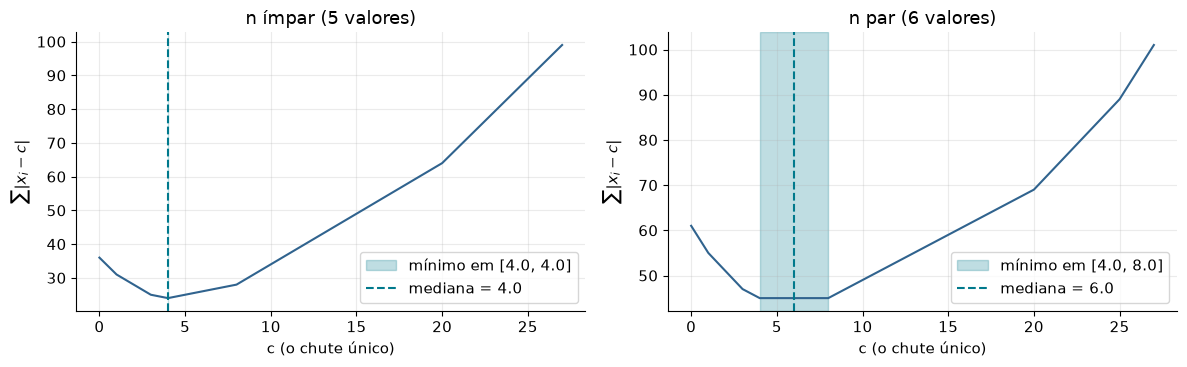

In [5]:
conjuntos = {
    "n ímpar (5 valores)": np.array([1, 3, 4, 8, 20]),
    "n par (6 valores)":   np.array([1, 3, 4, 8, 20, 25]),
}
cs = np.linspace(0, 27, 541)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nome, xx) in zip(axs, conjuntos.items()):
    f = np.array([np.abs(xx - c).sum() for c in cs])
    minimos = cs[np.isclose(f, f.min())]
    ax.plot(cs, f, color=COR["base"])
    ax.axvspan(minimos.min(), minimos.max(), color=COR["mediana"], alpha=0.25,
               label=f"mínimo em [{minimos.min():.1f}, {minimos.max():.1f}]")
    ax.axvline(np.median(xx), color=COR["mediana"], ls="--", label=f"mediana = {np.median(xx):.1f}")
    ax.set_title(nome); ax.set_xlabel("c (o chute único)"); ax.set_ylabel(r"$\sum |x_i - c|$"); ax.legend()
plt.tight_layout(); plt.show()

Com $n$ par o fundo da curva é **plano** entre os dois valores centrais (4 e 8). Qualquer ponto ali tem o mesmo erro absoluto total, e a mediana convencional (6) é o centro desse patamar.

### P2 · Invariância a transformações crescentes

Se $g$ é estritamente crescente, a ordem dos valores não muda, logo (para $n$ ímpar):

$$\text{mediana}\big(g(x_1), \dots, g(x_n)\big) = g\big(\text{mediana}(x_1, \dots, x_n)\big)$$

A média **não** tem essa propriedade: a média do logaritmo não é o logaritmo da média. Vamos testar com a renda (que tem 189 valores válidos, um número ímpar):

In [6]:
renda = df["renda_mensal"].dropna()
r = renda.to_numpy()
print(f"n = {len(r)} (ímpar: {len(r) % 2 == 1})\n")

print(f"mediana(log x)  = {np.median(np.log(r)):.6f}   |  log(mediana x) = {np.log(np.median(r)):.6f}   <- iguais")
print(f"média(log x)    = {np.mean(np.log(r)):.6f}   |  log(média x)   = {np.log(np.mean(r)):.6f}   <- diferentes")
assert np.isclose(np.median(np.log(r)), np.log(np.median(r)))

# Com n PAR, a propriedade vale só se a mediana for um valor observado (não o ponto médio)
par = np.array([1.0, 2.0, 3.0, 100.0])
print(f"\nn par: mediana(log x) = {np.median(np.log(par)):.4f} | log(mediana x) = {np.log(np.median(par)):.4f}   <- difere, pois a média dos dois centrais não é preservada")

n = 189 (ímpar: True)

mediana(log x)  = 8.333342   |  log(mediana x) = 8.333342   <- iguais
média(log x)    = 8.307844   |  log(média x)   = 8.497213   <- diferentes

n par: mediana(log x) = 0.8959 | log(mediana x) = 0.9163   <- difere, pois a média dos dois centrais não é preservada


> ⚠️ **Nuance.** Com $n$ par a mediana convencional é uma **média** dos dois centrais, e essa média **não** atravessa uma transformação não linear. A invariância é exata para $n$ ímpar (ou quando se usa a mediana inferior/superior, seção 8).

### P3 · Transformações afins sim, soma não

Para qualquer $a \neq 0$ e $b$: $\ \text{mediana}(a x + b) = a\,\text{mediana}(x) + b$. Mas **a mediana da soma não é a soma das medianas**, ao contrário da média (que é linear):

In [7]:
cambio = 0.18
assert np.isclose(np.median(r * cambio), cambio * np.median(r))
print(f"mediana em R$ = {np.median(r):.2f}  ->  em US$ = {np.median(r * cambio):.2f}  (= 0,18 x mediana em R$)")

x1, y1 = np.array([1, 2, 10]), np.array([10, 1, 2])
print(f"\nmediana(x) + mediana(y) = {np.median(x1)} + {np.median(y1)} = {np.median(x1) + np.median(y1)}")
print(f"mediana(x + y)          = mediana({x1 + y1}) = {np.median(x1 + y1)}")
print(f"média(x) + média(y)     = {x1.mean() + y1.mean():.2f}  |  média(x + y) = {(x1 + y1).mean():.2f}   <- a média é aditiva")

mediana em R$ = 4160.30  ->  em US$ = 748.85  (= 0,18 x mediana em R$)

mediana(x) + mediana(y) = 2.0 + 2.0 = 4.0
mediana(x + y)          = mediana([11  3 12]) = 11.0
média(x) + média(y)     = 8.67  |  média(x + y) = 8.67   <- a média é aditiva


### P4 · Robustez: influência limitada e ponto de ruptura de 50%

Dois experimentos com uma amostra de 101 valores (média 50, desvio 10):

- **(a) Curva de influência.** Trocamos **uma** observação por um valor $v$ e vemos o que acontece com a média e a mediana quando $v$ varia de −400 a +400.
- **(b) Ponto de ruptura.** Contaminamos uma fração crescente da amostra com o valor absurdo $10^6$ e observamos quando cada medida "quebra".

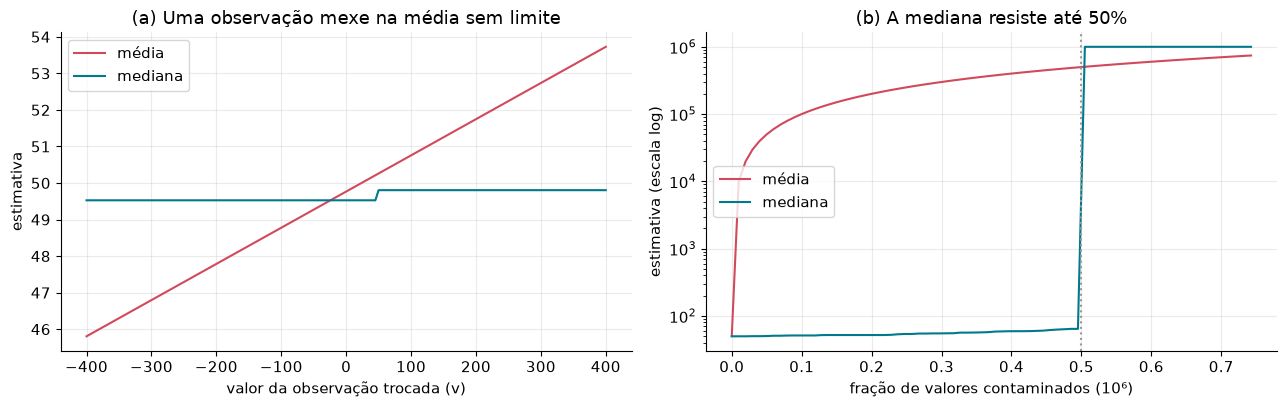

50 de 101 contaminados (49.5%): mediana = 64.2
51 de 101 contaminados (50.5%): mediana = 1000000   <- ruptura


In [8]:
g = np.random.default_rng(21)
base = g.normal(50, 10, 101)

# (a) influência de UMA observação
valores = np.linspace(-400, 400, 161)
resposta = np.array([[np.append(base[1:], v).mean(), np.median(np.append(base[1:], v))] for v in valores])

# (b) fração contaminada
n_amostra = len(base)
ks = np.arange(0, 76)
frac, medias_c, medianas_c = [], [], []
for k in ks:
    z = base.copy(); z[:k] = 1e6
    frac.append(k / n_amostra); medias_c.append(z.mean()); medianas_c.append(np.median(z))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(valores, resposta[:, 0], color=COR["media"], label="média")
axs[0].plot(valores, resposta[:, 1], color=COR["mediana"], label="mediana")
axs[0].set_xlabel("valor da observação trocada (v)"); axs[0].set_ylabel("estimativa")
axs[0].set_title("(a) Uma observação mexe na média sem limite"); axs[0].legend()

axs[1].semilogy(frac, medias_c, color=COR["media"], label="média")
axs[1].semilogy(frac, medianas_c, color=COR["mediana"], label="mediana")
axs[1].axvline(0.5, color="#999999", ls=":")
axs[1].set_xlabel("fração de valores contaminados (10⁶)"); axs[1].set_ylabel("estimativa (escala log)")
axs[1].set_title("(b) A mediana resiste até 50%"); axs[1].legend(loc="center left")
plt.tight_layout(); plt.show()

k50, k51 = 50, 51
z = base.copy(); z[:k50] = 1e6; med_50 = np.median(z)
z = base.copy(); z[:k51] = 1e6; med_51 = np.median(z)
print(f"{k50} de {n_amostra} contaminados ({k50 / n_amostra:.1%}): mediana = {med_50:.1f}")
print(f"{k51} de {n_amostra} contaminados ({k51 / n_amostra:.1%}): mediana = {med_51:.0f}   <- ruptura")

No painel (a), a média é uma **reta**: cada unidade a mais no valor trocado move a média em $1/n$, para sempre. A mediana é praticamente **plana**, porque a observação trocada só importa pela sua posição, e não pela sua magnitude. No painel (b), a mediana aguenta até **perto de metade** da amostra contaminada e só então quebra, enquanto a média quebra com **uma** observação. Dizemos que o **ponto de ruptura** da mediana é 50% (o máximo possível) e o da média é 0%.

### P5 · Média − mediana é um termômetro de assimetria

Em distribuições assimétricas, a cauda longa puxa a média na sua direção, mais do que puxa a mediana. Isso gera um diagnóstico rápido, o **segundo coeficiente de assimetria de Pearson**:

$$\text{sk}_P = \frac{3\,(\bar{x} - \tilde{x})}{s}$$

Além disso, vale sempre $|\bar{x} - \tilde{x}| \le s$: a média nunca se afasta da mediana mais que **um desvio padrão**.

In [9]:
g = np.random.default_rng(8)
dists = {
    "simétrica (normal)":          g.normal(0, 1, 20_000) + 5,
    "cauda à direita (lognormal)": g.lognormal(1.5, 0.6, 20_000),
    "cauda à esquerda (espelho)":  30 - g.lognormal(1.5, 0.6, 20_000),
}

linhas = []
for nome, v in dists.items():
    mu, md_, sd = v.mean(), np.median(v), v.std()
    assert abs(mu - md_) <= sd                       # a propriedade |média - mediana| <= desvio padrão
    linhas.append({"distribuição": nome, "média": mu, "mediana": md_, "desvio": sd,
                   "média − mediana": mu - md_, "Pearson 3(μ−m)/σ": 3 * (mu - md_) / sd})
tabela_assim = pd.DataFrame(linhas).set_index("distribuição")
display(tabela_assim.round(3))

mu_r, md_r, sd_r = r.mean(), np.median(r), r.std(ddof=1)
print(f"\nRenda real: média = {mu_r:.2f} | mediana = {md_r:.2f} | média − mediana = {mu_r - md_r:.2f}")
print(f"Pearson 3(média − mediana)/s = {3 * (mu_r - md_r) / sd_r:.3f}  -> positivo: cauda à direita")

,média,mediana,desvio,média − mediana,Pearson 3(μ−m)/σ
distribuição,,,,,
simétrica (normal),5.0030,5.0030,0.9950,0.0000,0.0000
cauda à direita (lognormal),5.3520,4.4810,3.4850,0.8710,0.7500
cauda à esquerda (espelho),24.5910,25.5020,3.5590,-0.9110,-0.7670



Renda real: média = 4901.09 | mediana = 4160.30 | média − mediana = 740.79
Pearson 3(média − mediana)/s = 0.687  -> positivo: cauda à direita


O sinal de $\bar{x} - \tilde{x}$ aponta para o lado da cauda: **positivo** (cauda à direita), **próximo de zero** (simétrica), **negativo** (cauda à esquerda). A renda real do nosso dataset confirma o padrão típico de renda, com cauda à direita. Voltaremos ao coeficiente de assimetria completo na aula de Assimetria e Curtose.

### P6 · O preço da robustez: eficiência estatística

A mediana é robusta, mas **não é de graça**. Se os dados forem bem comportados (normais), a mediana amostral flutua **mais** do que a média de um conjunto para outro, ou seja, desperdiça informação. Se os dados tiverem caudas pesadas ou contaminação, o jogo se inverte. Vamos medir isso por simulação, comparando a variância da média com a da mediana em muitas amostras repetidas:

$$\text{razão} = \frac{\text{Var}(\bar{x})}{\text{Var}(\tilde{x})} \qquad \begin{cases} < 1 & \text{a média é mais precisa} \\ > 1 & \text{a mediana é mais precisa} \end{cases}$$

In [10]:
def razao_variancias(gerador, n=101, reps=5000, semente=0):
    g = np.random.default_rng(semente)
    amostras = gerador(g, (reps, n))
    return amostras.mean(axis=1).var() / np.median(amostras, axis=1).var()

def normal_contaminada(g, shape):                    # 90% N(0,1) + 10% N(0,10)
    base_ = g.normal(0, 1, shape)
    ruim = g.random(shape) < 0.10
    return np.where(ruim, g.normal(0, 10, shape), base_)

cenarios = {
    "Uniforme (sem caudas)":         lambda g, s: g.uniform(-1, 1, s),
    "Normal":                        lambda g, s: g.normal(0, 1, s),
    "t de Student (3 g.l.)":         lambda g, s: g.standard_t(3, s),
    "Laplace (caudas exponenciais)": lambda g, s: g.laplace(0, 1, s),
    "Normal contaminada (10%)":      normal_contaminada,
}
eficiencia = pd.Series({nome: razao_variancias(ger) for nome, ger in cenarios.items()}, name="Var(média) / Var(mediana)")
eficiencia.round(3).to_frame()

,Var(média) / Var(mediana)
Uniforme (sem caudas),0.3340
Normal,0.6330
t de Student (3 g.l.),1.6100
Laplace (caudas exponenciais),1.6610
Normal contaminada (10%),5.6440


Leia a tabela com cuidado:

- Na **Normal**, a razão fica perto de $2/\pi \approx 0{,}64$: a mediana tem só cerca de **64% da eficiência** da média. Para atingir a mesma precisão, ela precisaria de uns 57% mais dados.
- Na **Uniforme**, a mediana se sai ainda pior.
- Com **caudas pesadas** (t, Laplace) ou **contaminação**, a razão passa de 1: aí a **mediana é a mais precisa**, e por larga margem na normal contaminada.

> 🧠 **A lição.** Não existe "melhor medida" em abstrato. Há um equilíbrio entre **eficiência** (extrair o máximo de dados limpos) e **robustez** (sobreviver a dados sujos). Média e mediana estão nos dois extremos, e a **média truncada** (próxima aula) fica no meio do caminho.

### Média e mediana lado a lado

| | Média | Mediana |
|---|---|---|
| **Depende de** | todos os valores | só da ordem (dos valores centrais) |
| **Minimiza** | erro quadrático | erro absoluto |
| **Ponto de ruptura** | 0% | 50% |
| **Aditividade** | linear (soma das médias = média da soma) | não aditiva |
| **Eficiência na Normal** | 100% | ≈ 64% |
| **Pontos fracos** | outliers e caudas longas | cega à magnitude dos extremos; menos precisa em dados limpos |
| **Use quando** | dados simétricos e limpos, somas fazem sentido | assimetria, outliers, dados ordinais |

---
# ATO III · COMO
## 5 · Na mão

Antes de qualquer biblioteca, papel e lápis.

**Caso 1: $n$ ímpar.** Notas `[7, 3, 9, 5, 8]`.

1. Ordene: `[3, 5, 7, 8, 9]`
2. $n = 5$, posição central $(5+1)/2 = 3$
3. Mediana $= x_{(3)} = \mathbf{7}$

**Caso 2: $n$ par.** Notas `[12, 4, 9, 7, 15, 6]`.

1. Ordene: `[4, 6, 7, 9, 12, 15]`
2. $n = 6$, posições centrais $n/2 = 3$ e $n/2+1 = 4$
3. Mediana $= \dfrac{x_{(3)} + x_{(4)}}{2} = \dfrac{7 + 9}{2} = \mathbf{8}$ (um valor que **não está** na amostra)

**Caso 3: dados agrupados.** Rendas de 120 clientes, em classes de R$ mil:

| Classe | 0–2 | 2–4 | 4–6 | 6–8 | 8–10 |
|---|---|---|---|---|---|
| Frequência $f$ | 20 | 45 | 30 | 15 | 10 |
| Acumulada | 20 | 65 | 95 | 110 | 120 |

A posição alvo é $n/2 = 60$. A primeira classe cuja acumulada atinge 60 é **2–4** (acumulada anterior $F_{\text{ant}} = 20$, $f_{\text{med}} = 45$, $h = 2$):

$$\tilde{x} = 2 + \frac{60 - 20}{45}\cdot 2 = 2 + 1{,}778 = \mathbf{3{,}778}$$

Agora em Python **puro**:

In [11]:
def mediana(x):
    """Mediana em Python puro (ordena e indexa)."""
    n = len(x)
    if n == 0:
        raise ValueError("a lista está vazia")
    s = sorted(x)
    meio = n // 2
    return s[meio] if n % 2 == 1 else (s[meio - 1] + s[meio]) / 2


def mediana_agrupada(limites, freq):
    """Mediana de dados agrupados por interpolação linear dentro da classe mediana."""
    n = sum(freq)
    alvo, acumulada = n / 2, 0
    for i, f in enumerate(freq):
        if f > 0 and acumulada + f >= alvo:
            L, h = limites[i], limites[i + 1] - limites[i]
            return L + (alvo - acumulada) / f * h
        acumulada += f


def mediana_ponderada(x, w):
    """Mediana ponderada: menor x cujo peso acumulado atinge 50% do peso total."""
    if len(x) != len(w) or len(x) == 0:
        raise ValueError("x e w precisam ter o mesmo tamanho (e não ser vazios)")
    if any(p < 0 for p in w) or sum(w) == 0:
        raise ValueError("pesos inválidos")
    pares = sorted(zip(x, w))
    total, acumulado = sum(w), 0
    for valor, peso in pares:
        acumulado += peso
        if acumulado >= total / 2:
            return valor


print("Caso 1 (ímpar)  :", mediana([7, 3, 9, 5, 8]))
print("Caso 2 (par)    :", mediana([12, 4, 9, 7, 15, 6]))
print("Caso 3 (agrupado):", round(mediana_agrupada([0, 2, 4, 6, 8, 10], [20, 45, 30, 15, 10]), 4))
print("Ponderada       :", mediana_ponderada([1, 2, 3], [1, 1, 5]), "(o valor 3 pesa 5 de 7)")

Caso 1 (ímpar)  : 7
Caso 2 (par)    : 8.0
Caso 3 (agrupado): 3.7778
Ponderada       : 3 (o valor 3 pesa 5 de 7)


In [12]:
# Testes: precisamos concordar com o NumPy e falhar com clareza nos casos de borda
assert mediana([7, 3, 9, 5, 8]) == np.median([7, 3, 9, 5, 8]) == 7
assert mediana([12, 4, 9, 7, 15, 6]) == np.median([12, 4, 9, 7, 15, 6]) == 8
assert np.isclose(mediana_agrupada([0, 2, 4, 6, 8, 10], [20, 45, 30, 15, 10]), 3.7778, atol=1e-4)
assert mediana_ponderada([1, 2, 3], [1, 1, 1]) == 2                  # pesos iguais = mediana simples (n ímpar)

for _ in range(300):
    amostra = rng.integers(0, 1000, size=rng.integers(1, 60)).tolist()
    assert np.isclose(mediana(amostra), np.median(amostra))

try:
    mediana([])
except ValueError as erro:
    print("OK  lista vazia ->", erro)

OK  lista vazia -> a lista está vazia


### Bônus de engenharia: mediana sem ordenar tudo (seleção em tempo linear)

Ordenar $n$ valores custa $O(n \log n)$, mas para achar **um** elemento de posição $k$ não precisamos ordenar tudo. O algoritmo ***quickselect*** escolhe um pivô, separa os valores em menores, iguais e maiores, e **descarta** o lado que não contém a posição $k$. Em média custa $O(n)$.

In [13]:
def quickselect(a, k, semente=0):
    """k-ésimo menor elemento (k começa em 0), sem ordenar a lista inteira."""
    sorteio = np.random.default_rng(semente)
    a = list(a)
    while True:
        pivo = a[sorteio.integers(len(a))]
        menores = [v for v in a if v < pivo]
        iguais  = [v for v in a if v == pivo]
        if k < len(menores):
            a = menores
        elif k < len(menores) + len(iguais):
            return pivo
        else:
            k -= len(menores) + len(iguais)
            a = [v for v in a if v > pivo]


def mediana_quickselect(x):
    n = len(x)
    if n % 2 == 1:
        return quickselect(x, n // 2)
    return (quickselect(x, n // 2 - 1) + quickselect(x, n // 2)) / 2


for _ in range(300):
    amostra = rng.integers(0, 50, size=rng.integers(1, 80)).tolist()     # muitos empates de propósito
    assert np.isclose(mediana_quickselect(amostra), np.median(amostra))
print("quickselect confere com np.median em 300 amostras aleatórias (com empates).")

# Quanto custa ordenar tudo vs. selecionar só a posição central?
grande = rng.normal(size=2_000_000)
k = len(grande) // 2

def melhor_tempo(f, repeticoes=5):
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); f(); tempos.append(time.perf_counter() - t0)
    return min(tempos)

t_ordenar = melhor_tempo(lambda: np.sort(grande)[k])
t_selecao = melhor_tempo(lambda: np.partition(grande, k)[k])
print(f"\nordenar tudo (np.sort)        : {t_ordenar * 1000:7.1f} ms")
print(f"selecionar só a posição (np.partition): {t_selecao * 1000:7.1f} ms   ({t_ordenar / t_selecao:.1f}x mais rápido)")

quickselect confere com np.median em 300 amostras aleatórias (com empates).

ordenar tudo (np.sort)        :    25.0 ms
selecionar só a posição (np.partition):     8.2 ms   (3.1x mais rápido)


O `np.median` usa justamente a **seleção** (`np.partition`), e não a ordenação completa. Isso importa quando você calcula medianas de milhões de linhas ou dentro de laços (como filtros em janelas deslizantes).

---
## 6 · Em Python: NumPy, Pandas e `statistics`

Mais uma vez o ponto crítico é o comportamento diante de `NaN`. O nosso dataset tem 11 rendas ausentes:

In [14]:
renda_col = df["renda_mensal"]           # 11 valores ausentes
arr = renda_col.to_numpy()

print(f"np.median(Series do Pandas)       : {np.median(renda_col)}")
print(f"np.median(array NumPy)            : {np.median(arr)}")
print(f"np.nanmedian(array NumPy)         : {np.nanmedian(arr):.2f}")
print(f"Series.median()                   : {renda_col.median():.2f}")
print(f"Series.median(skipna=False)       : {renda_col.median(skipna=False)}")
print(f"statistics.median (sem NaN)       : {statistics.median(renda_col.dropna()):.2f}")
print(f"statistics.median_low / _high     : {statistics.median_low(renda_col.dropna()):.2f} / {statistics.median_high(renda_col.dropna()):.2f}")

np.median(Series do Pandas)       : nan
np.median(array NumPy)            : nan
np.nanmedian(array NumPy)         : 4160.30
Series.median()                   : 4160.30
Series.median(skipna=False)       : nan
statistics.median (sem NaN)       : 4160.30
statistics.median_low / _high     : 4160.30 / 4160.30


> ⚠️ **Armadilha.** Com `NaN` presente, `np.median` devolve `nan` (inclusive numa `Series`), enquanto `Series.median()` ignora os ausentes por padrão. Na aula de média, `np.mean` se comportava de **outro** jeito com a `Series`. **Cada função trata `NaN` à sua maneira**, então escolha de propósito: `np.nanmedian`, `Series.median(skipna=True)` ou `dropna()` explícito.

### Mediana por grupo: o relatório que a diretoria deveria ver

Em vez de só a média, uma tabela com **n, média, mediana e quartis** por categoria. A coluna `média − mediana` é o termômetro de assimetria que vimos na seção 4:

In [15]:
resumo = df.groupby("categoria_frequente", observed=True)["renda_mensal"].agg(
    n="count",
    media="mean",
    mediana="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
)
resumo["media_menos_mediana"] = resumo["media"] - resumo["mediana"]
resumo.round(2)

,n,media,mediana,q1,q3,media_menos_mediana
categoria_frequente,,,,,,
Alimentos,22,4801.7100,4146.3400,2897.6900,5860.4400,655.3600
Eletrônicos,57,5000.6900,3771.4300,2502.3100,7014.5300,1229.2600
Livros,30,4178.6500,3823.4900,2300.4500,5254.2100,355.1600
Roupas,80,5128.3800,4495.9100,2800.2000,6683.5300,632.4700


Todas as categorias têm média **acima** da mediana, o que é coerente com a cauda à direita da renda. Para dados agrupados, o módulo `statistics` tem `median_grouped`, que recebe os **pontos médios** das classes repetidos pelas frequências e a amplitude da classe. Ele deve concordar com a nossa implementação manual:

In [16]:
pontos_medios = [1] * 20 + [3] * 45 + [5] * 30 + [7] * 15 + [9] * 10      # os valores 1, 3, 5, 7, 9 são os centros das classes
da_biblioteca = statistics.median_grouped(pontos_medios, interval=2)
manual = mediana_agrupada([0, 2, 4, 6, 8, 10], [20, 45, 30, 15, 10])
print(f"statistics.median_grouped = {da_biblioteca:.4f}  |  nossa mediana_agrupada = {manual:.4f}")
assert np.isclose(da_biblioteca, manual)

statistics.median_grouped = 3.7778  |  nossa mediana_agrupada = 3.7778


---
## 7 · Visualizando

A mediana é a linha central de todo **boxplot**. Vamos ver a ECDF da renda e os boxplots por categoria, com a média marcada por um losango. Quando o losango fica acima da linha central, a média está sendo puxada pela cauda:

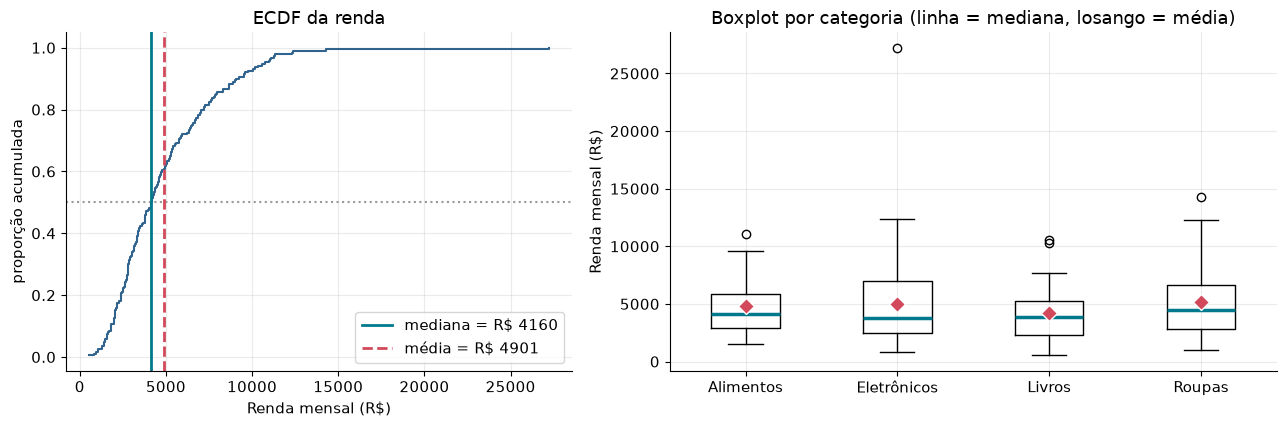

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})

# (a) ECDF da renda com a mediana
xs_r = np.sort(r)
axs[0].step(xs_r, np.arange(1, len(xs_r) + 1) / len(xs_r), where="post", color=COR["base"])
axs[0].axhline(0.5, color="#999999", ls=":")
axs[0].axvline(np.median(r), color=COR["mediana"], lw=2, label=f"mediana = R$ {np.median(r):.0f}")
axs[0].axvline(r.mean(), color=COR["media"], lw=2, ls="--", label=f"média = R$ {r.mean():.0f}")
axs[0].set_xlabel("Renda mensal (R$)"); axs[0].set_ylabel("proporção acumulada")
axs[0].set_title("ECDF da renda"); axs[0].legend(loc="lower right")

# (b) boxplot por categoria, com a média como losango
nomes = sorted(df["categoria_frequente"].unique())
grupos = [df.loc[df["categoria_frequente"] == c, "renda_mensal"].dropna().to_numpy() for c in nomes]
axs[1].boxplot(grupos, showmeans=True,
               medianprops={"color": COR["mediana"], "lw": 2.5},
               meanprops={"marker": "D", "markerfacecolor": COR["media"], "markeredgecolor": "white", "markersize": 8})
axs[1].set_xticks(range(1, len(nomes) + 1)); axs[1].set_xticklabels(nomes)
axs[1].set_ylabel("Renda mensal (R$)"); axs[1].set_title("Boxplot por categoria (linha = mediana, losango = média)")
plt.tight_layout(); plt.show()

E o termômetro de assimetria em ação, com as três distribuições simuladas da seção 4 (P5). A relação entre a média e a mediana **muda de lado** conforme a cauda:

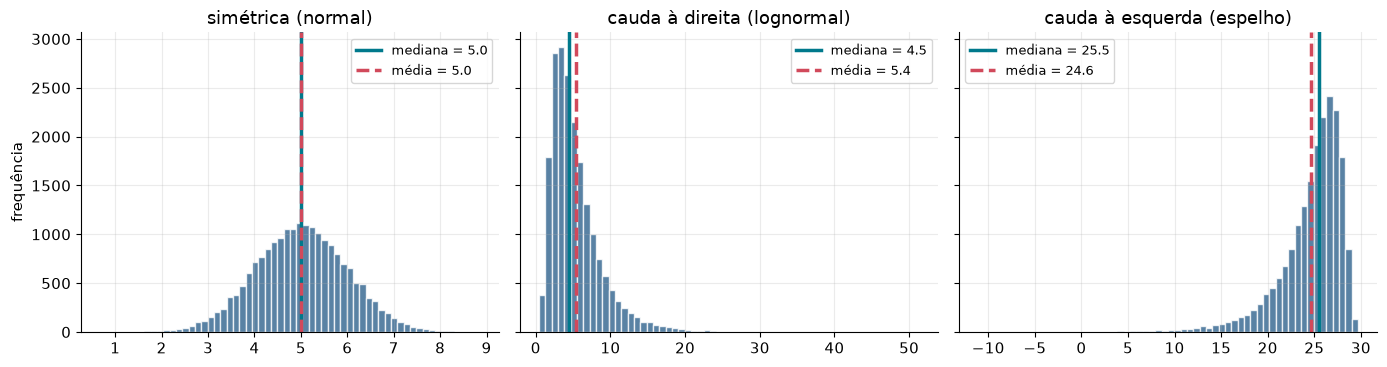

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (nome, v) in zip(axs, dists.items()):
    ax.hist(v, bins=60, color=COR["base"], alpha=0.8, edgecolor="white")
    ax.axvline(np.median(v), color=COR["mediana"], lw=2.5, label=f"mediana = {np.median(v):.1f}")
    ax.axvline(v.mean(), color=COR["media"], lw=2.5, ls="--", label=f"média = {v.mean():.1f}")
    ax.set_title(nome); ax.legend(fontsize=9)
axs[0].set_ylabel("frequência")
plt.tight_layout(); plt.show()

---
# ATO IV · CUIDADO
## 8 · Armadilhas e limites

A mediana tem fama de "medida segura", e justamente por isso se erra com ela sem perceber. Sete armadilhas.

### 8.1 · Mediana de medianas

> ⚠️ Na Aula 01 aprendemos que a média geral é a **média ponderada** das médias dos grupos. Com a mediana **não existe** fórmula equivalente: a mediana geral **não pode ser reconstruída** a partir das medianas dos grupos, com ou sem pesos.

Um exemplo pequeno, onde conhecemos tudo:

In [19]:
g1 = np.array([1, 2, 3])                          # mediana 2
g2 = np.array([10, 20, 30, 40, 50, 60, 70])       # mediana 40
todos = np.concatenate([g1, g2])
meds, ns = [np.median(g1), np.median(g2)], [len(g1), len(g2)]

print(f"Mediana geral (a verdade)                : {np.median(todos):.1f}")
print(f"Mediana das medianas                     : {np.median(meds):.1f}")
print(f"Mediana ponderada das medianas (pelo n)  : {mediana_ponderada(meds, ns):.1f}")
print(f"Média ponderada das medianas (pelo n)    : {np.average(meds, weights=ns):.1f}")

Mediana geral (a verdade)                : 25.0
Mediana das medianas                     : 21.0
Mediana ponderada das medianas (pelo n)  : 40.0
Média ponderada das medianas (pelo n)    : 28.6


In [20]:
# E com o dataset real
por_cat = df.dropna(subset=["renda_mensal"]).groupby("categoria_frequente")["renda_mensal"].agg(["median", "count"])
print(f"Mediana geral da renda                   : {np.median(r):.2f}")
print(f"Mediana das medianas dos grupos          : {por_cat['median'].median():.2f}")
print(f"Mediana ponderada das medianas (pelo n)  : {mediana_ponderada(por_cat['median'].tolist(), por_cat['count'].tolist()):.2f}")

Mediana geral da renda                   : 4160.30
Mediana das medianas dos grupos          : 3984.92
Mediana ponderada das medianas (pelo n)  : 4146.35


Nenhuma combinação recupera o valor verdadeiro (no exemplo pequeno, a verdade é 25 e as aproximações dão 21, 40 e 28,6). Para a mediana geral, **você precisa dos dados individuais** (ou de uma estrutura de resumo como *quantile sketches*, seção 11).

### 8.2 · A mediana não é aditiva

> ⚠️ Em um processo com etapas em sequência, o **tempo total típico** não é a soma dos tempos **típicos** das etapas, mas apenas a **média** é aditiva.

In [21]:
coleta     = rng.lognormal(mean=1.0, sigma=0.8, size=100_000)     # minutos
transporte = rng.lognormal(mean=2.0, sigma=0.6, size=100_000)
total = coleta + transporte

print(f"soma das medianas  = {np.median(coleta):.2f} + {np.median(transporte):.2f} = {np.median(coleta) + np.median(transporte):.2f} min")
print(f"mediana do total   = {np.median(total):.2f} min   <- diferente")
print(f"\nsoma das médias    = {coleta.mean() + transporte.mean():.2f} min")
print(f"média do total     = {total.mean():.2f} min   <- igual (a média é aditiva)")
assert np.isclose(coleta.mean() + transporte.mean(), total.mean())

soma das medianas  = 2.73 + 7.41 = 10.14 min
mediana do total   = 11.08 min   <- diferente

soma das médias    = 12.63 min
média do total     = 12.63 min   <- igual (a média é aditiva)


Com variáveis assimétricas, a soma das medianas **subestima** a mediana do total. Em orçamentos de latência ("cada etapa leva p50 = 20 ms, logo o total é 100 ms") esse erro vira promessa quebrada.

### 8.3 · Empates e variáveis discretas: baixa resolução

In [22]:
grupo_a = np.array([4] * 10)                         # todos dão nota 4
grupo_b = np.array([1] * 4 + [4] * 2 + [5] * 4)      # 40% dão nota 1, 40% dão nota 5

for nome, g_ in [("A", grupo_a), ("B", grupo_b)]:
    print(f"Grupo {nome}: mediana = {np.median(g_):.1f} | média = {g_.mean():.1f} | % de notas <= 2: {(g_ <= 2).mean():.0%}")

Grupo A: mediana = 4.0 | média = 4.0 | % de notas <= 2: 0%
Grupo B: mediana = 4.0 | média = 3.2 | % de notas <= 2: 40%


Mesma mediana (4), públicos opostos. Em escalas curtas (1 a 5) a mediana é um número inteiro que **esconde** praticamente tudo. Complemente-a com a **distribuição** das notas ou com a proporção de cada categoria.

### 8.4 · NaN em implementações "caseiras"

> ⚠️ A nossa `mediana` em Python puro ordena com `sorted`. Com `NaN` na lista, as comparações com `NaN` são sempre falsas, e a ordenação **fica sem sentido, em silêncio**:

In [23]:
nan = float("nan")
variacoes = {
    "NaN no meio ": [3.0, nan, 1.0, 2.0, 5.0],
    "NaN no início": [nan, 3.0, 1.0, 2.0, 5.0],
    "NaN no fim   ": [3.0, 1.0, 2.0, 5.0, nan],
}
for nome, lista in variacoes.items():
    print(f"{nome}: mediana (nossa) = {mediana(lista)}")
print(f"\ncorreto (np.nanmedian dos mesmos valores): {np.nanmedian([3.0, 1.0, 2.0, 5.0])}")

NaN no meio : mediana (nossa) = 1.0
NaN no início: mediana (nossa) = 2.0
NaN no fim   : mediana (nossa) = 3.0

correto (np.nanmedian dos mesmos valores): 2.5


O resultado depende de **onde** o `NaN` está na lista, o que é pior do que dar erro: a função parece funcionar. Em código de produção, valide ou filtre os ausentes **antes** de calcular.

### 8.5 · Com $n$ par a mediana pode não existir nos dados (variáveis ordinais)

Para valores inteiros ou categorias ordenadas, a média dos dois centrais pode ser uma nota que **ninguém deu**:

In [24]:
notas = [1, 2, 4, 5]
print(f"median      = {statistics.median(notas)}   <- ninguém deu nota 3")
print(f"median_low  = {statistics.median_low(notas)}")
print(f"median_high = {statistics.median_high(notas)}")

median      = 3.0   <- ninguém deu nota 3
median_low  = 2
median_high = 4


Em dados **ordinais** (escalas, níveis de severidade), prefira `median_low` ou `median_high`, que sempre devolvem um valor observado.

### 8.6 · A mediana é cega à magnitude dos extremos

> ⚠️ A mesma propriedade que a protege de outliers a impede de ver mudanças **reais** nas caudas. Um sistema pode piorar muito para 5% dos usuários sem a mediana se mexer:

In [25]:
antes  = rng.lognormal(mean=4.0, sigma=0.5, size=20_000)           # latências em ms
depois = antes.copy()
afetados = rng.choice(len(depois), size=int(0.05 * len(depois)), replace=False)
depois[afetados] *= 10                                               # 5% das requisições ficam 10x mais lentas

painel = pd.DataFrame({
    "mediana": [np.median(antes), np.median(depois)],
    "média":   [antes.mean(), depois.mean()],
    "p95":     [np.percentile(antes, 95), np.percentile(depois, 95)],
    "p99":     [np.percentile(antes, 99), np.percentile(depois, 99)],
}, index=["antes", "depois"])
painel["variação da mediana"] = ["", f"{painel.loc['depois', 'mediana'] / painel.loc['antes', 'mediana'] - 1:+.1%}"]
painel

,mediana,média,p95,p99,variação da mediana
antes,54.3356,61.6794,122.7577,174.8569,
depois,56.1569,89.5960,229.3812,827.0589,+3.4%


A mediana quase não saiu do lugar, enquanto a média e os percentis altos denunciam o problema. Por isso, **monitoramento** usa a mediana **junto** com p95 e p99, nunca sozinha.

### 8.7 · Distribuições bimodais: o centro pode ser um vazio

In [26]:
bimodal = np.concatenate([rng.normal(20, 3, 500), rng.normal(80, 3, 500)])
md_b, mu_b = np.median(bimodal), bimodal.mean()
perto = (np.abs(bimodal - md_b) <= 10).mean()

print(f"mediana = {md_b:.1f} | média = {mu_b:.1f}")
print(f"proporção de observações a menos de 10 unidades da mediana: {perto:.1%}")

mediana = 50.2 | média = 50.0
proporção de observações a menos de 10 unidades da mediana: 0.0%


Com duas "populações" misturadas, a mediana (e a média) cai no **vale entre os dois picos**, onde praticamente não há dados. Nenhum cliente é "típico" nesse valor. A lição: **olhe o histograma antes de resumir**.

### Resumo das armadilhas

| Armadilha | Sintoma | Remédio |
|---|---|---|
| Mediana de medianas | "mediana geral" que não bate com o dado bruto | usar os dados individuais ou *quantile sketches* |
| Não aditiva | soma das medianas ≠ mediana do total | simular/convoluir as distribuições; usar a média para somas |
| Empates e escalas curtas | grupos diferentes com a mesma mediana | mostrar a distribuição completa |
| NaN em código caseiro | resultado depende da posição do NaN | filtrar antes; `np.nanmedian` |
| $n$ par com ordinais | mediana que não existe nos dados | `median_low` / `median_high` |
| Cegueira às caudas | mediana estável com a cauda piorando | acompanhar p95 e p99 |
| Bimodalidade | "valor típico" em uma região vazia | histograma, separar as subpopulações |

# ATO V · ONDE SE APLICA

## 9 · No trabalho, por área

### 9.1 · Análise de Dados: relatório e SQL

🏭 No trabalho. O relatório que a diretoria deveria receber é a tabela da seção 6: \(n\), média, mediana e quartis por grupo. Quando média e mediana divergem muito, o analista já sabe que há assimetria ou outliers, antes de qualquer gráfico.

### 9.2 · Ciência de Dados: imputação, outliers e escalonamento robusto

🏭 No trabalho. Três usos diários da mediana: preencher ausentes, detectar anomalias e escalar variáveis.

**(a) Imputação pela mediana do grupo.** Preencher com a mediana da categoria mantém a estrutura entre os grupos, o que um valor global não faz:


In [27]:
mediana_grupo = df.groupby("categoria_frequente")["renda_mensal"].transform("median")
renda_imp = df["renda_mensal"].fillna(mediana_grupo)
print(f"Ausentes antes: {df['renda_mensal'].isna().sum()} | depois: {renda_imp.isna().sum()}")

Ausentes antes: 11 | depois: 0


**(b) Detecção de outliers com a mediana e o MAD.** O MAD (Median Absolute Deviation) é a mediana dos desvios absolutos em torno da mediana. Com ele se define o z modificado (Iglewicz e Hoaglin), em que a constante $0{,}6745 = 1/1{,}4826$ torna o MAD comparável ao desvio padrão de uma Normal:

$$\text{MAD} = \text{mediana}\big(|x_i - \tilde{x}|\big) \qquad M_i = \frac{0{,}6745\,(x_i - \tilde{x})}{\text{MAD}} \qquad \text{outlier se } |M_i| > 3{,}5$$

In [28]:
med = np.median(r)
mad = np.median(np.abs(r - med))
z_classico = (r - r.mean()) / r.std(ddof=0)
z_robusto = 0.6745 * (r - med) / mad
q1, q3 = np.percentile(r, [25, 75])
iqr = q3 - q1

marcados = pd.DataFrame({
    "|z| > 3 (clássico)":   np.abs(z_classico) > 3,
    "|M| > 3,5 (robusto)":  np.abs(z_robusto) > 3.5,
    "regra do IQR (1,5)":   (r < q1 - 1.5 * iqr) | (r > q3 + 1.5 * iqr)
})

print(f"mediana = {med:.2f} | MAD = {mad:.2f} | IQR = {iqr:.2f}\n")
print("Quantos valores cada regra marca como outlier:")
print(marcados.sum().to_string())

mediana = 4160.30 | MAD = 1722.05 | IQR = 3816.33

Quantos valores cada regra marca como outlier:
|z| > 3 (clássico)     1
|M| > 3,5 (robusto)    2
regra do IQR (1,5)     4


Compare as contagens. O z clássico usa a média e o desvio padrão, justamente as medidas mais contaminadas pelos próprios outliers (o outlier infla o desvio e se esconde, o chamado mascaramento). O z robusto usa mediana e MAD, que quase não são afetados.

**(c) Escalonamento robusto.** O `StandardScaler` centra na média e divide pelo desvio padrão. O `RobustScaler` centra na mediana e divide pelo IQR:


In [30]:
from sklearn.preprocessing import RobustScaler, StandardScaler

X = r.reshape(-1, 1)
for nome, escalador in [("StandardScaler", StandardScaler()), ("RobustScaler (mediana/IQR)", RobustScaler())]:
    z = escalador.fit_transform(X)[:, 0]
    iqr_z = np.subtract(*np.percentile(z, [75, 25]))
    print(f"{nome:<28} IQR dos dados escalados = {iqr_z:.2f} | maior valor = {z.max():.2f}")

# O que acontece com os parâmetros de cada escalador se removermos o maior valor (o outlier)?
sem_topo = np.sort(r)[:-1]
iqr_sem = np.subtract(*np.percentile(sem_topo, [75, 25]))
variacao = lambda antes, depois: (depois - antes) / antes
print("\nVariação dos parâmetros ao remover o maior valor:")
print(f"  StandardScaler -> média {variacao(r.mean(), sem_topo.mean()):+.1%} | desvio padrão {variacao(r.std(), sem_topo.std()):+.1%}")
print(f"  RobustScaler   -> mediana {variacao(np.median(r), np.median(sem_topo)):+.1%} | IQR {variacao(iqr, iqr_sem):+.1%}")

StandardScaler               IQR dos dados escalados = 1.18 | maior valor = 6.92
RobustScaler (mediana/IQR)   IQR dos dados escalados = 1.00 | maior valor = 6.05

Variação dos parâmetros ao remover o maior valor:
  StandardScaler -> média -2.4% | desvio padrão -13.4%
  RobustScaler   -> mediana -0.2% | IQR -1.0%


O `RobustScaler` garante amplitude interquartil 1 na parte central dos dados, e os seus parâmetros (mediana e IQR) quase não mudam quando um outlier entra ou sai. Os do `StandardScaler` (média e desvio padrão) mudam bem mais. Em dados com outliers, isso torna o escalonamento robusto mais estável entre treino e produção.

---

### 9.3 · Machine Learning: baseline, regressão por mediana e ensembles

🏭 No trabalho. Cada métrica de erro tem o seu "melhor chute único". Para o erro absoluto (MAE) é a mediana, para o erro quadrático (MSE) é a média:


In [31]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

y = r.copy()
x0 = np.zeros((len(y), 1))
resultados = {}
for estrategia in ["mean", "median"]:
    pred = DummyRegressor(strategy=estrategia).fit(x0, y).predict(x0)
    resultados[estrategia] = (mean_absolute_error(y, pred), mean_squared_error(y, pred))
    print(f"baseline pela {estrategia:<6}: MAE = {resultados[estrategia][0]:8.2f} | MSE = {resultados[estrategia][1]:12.2f}")

assert resultados["median"][0] < resultados["mean"][0]
assert resultados["mean"][1] < resultados["median"][1]

baseline pela mean  : MAE =  2377.95 | MSE =  10413612.37
baseline pela median: MAE =  2286.14 | MSE =  10962385.17


Regressão por mediana (LAD). Minimizar o erro absoluto, em vez do quadrático, dá a regressão quantílica com $\tau = 0{,}5$: a reta prevê a mediana condicional e resiste a outliers. Veja contra os mínimos quadrados (OLS), com 6% de outliers positivos injetados:

verdade : intercepto = 1.00 | inclinação = 2.00
OLS     : intercepto = 5.16 | inclinação = 1.85
LAD     : intercepto = 1.08 | inclinação = 2.01


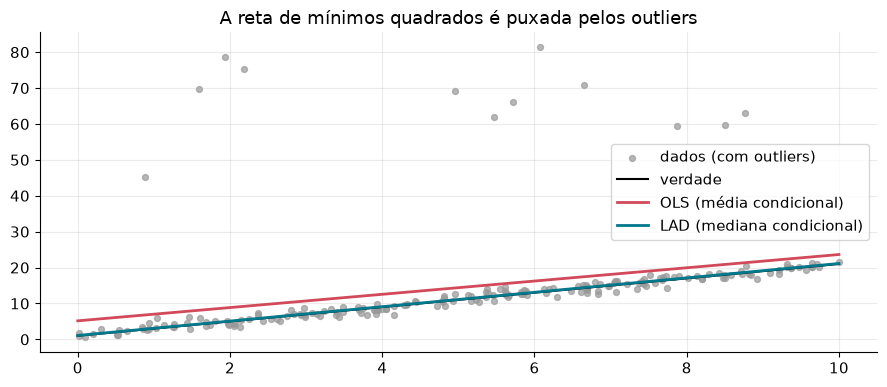

In [32]:
from sklearn.linear_model import LinearRegression, QuantileRegressor

g = np.random.default_rng(3)
x = g.uniform(0, 10, 200)
y_limpo = 2 * x + 1 + g.normal(0, 1, 200)          # verdade: intercepto 1, inclinação 2
y_sujo = y_limpo.copy()
indices = g.choice(200, size=12, replace=False)
y_sujo[indices] += g.uniform(40, 80, 12)           # 12 outliers (6%)

ols = LinearRegression().fit(x.reshape(-1, 1), y_sujo)
lad = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs").fit(x.reshape(-1, 1), y_sujo)
print("verdade : intercepto = 1.00 | inclinação = 2.00")
print(f"OLS     : intercepto = {ols.intercept_:.2f} | inclinação = {ols.coef_[0]:.2f}")
print(f"LAD     : intercepto = {lad.intercept_:.2f} | inclinação = {lad.coef_[0]:.2f}")
assert abs(lad.intercept_ - 1) < abs(ols.intercept_ - 1)

xs_plot = np.linspace(0, 10, 50)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(x, y_sujo, s=18, color="#999999", alpha=0.7, label="dados (com outliers)")
ax.plot(xs_plot, 2 * xs_plot + 1, color="black", lw=1.5, label="verdade")
ax.plot(xs_plot, ols.predict(xs_plot.reshape(-1, 1)), color=COR["media"], lw=2, label="OLS (média condicional)")
ax.plot(xs_plot, lad.predict(xs_plot.reshape(-1, 1)), color=COR["mediana"], lw=2, label="LAD (mediana condicional)")
ax.set_title("A reta de mínimos quadrados é puxada pelos outliers"); ax.legend()
plt.tight_layout(); plt.show()

Ensembles robustos. Se um dos modelos quebra (um bug de feature, um dado fora de distribuição), a média das previsões acompanha o erro e a mediana não:

In [33]:
previsoes = np.array([10.1, 9.8, 10.3, 9.9, 10.0, 10.2, 250.0])     # o 7º modelo quebrou
print(f"média das previsões   = {previsoes.mean():.1f}")
print(f"mediana das previsões = {np.median(previsoes):.1f}")

média das previsões   = 44.3
mediana das previsões = 10.1


### 9.4 · Deep Learning e Visão Computacional: perda L1 e filtro de mediana

🏭 No trabalho (DL). A perda L1 / MAE (`nn.L1Loss`) treina a rede para prever a mediana condicional, e por isso é mais robusta a rótulos ruidosos do que o MSE (média condicional). A perda Huber é um meio-termo: quadrática perto de zero e linear longe.

🏭 No trabalho (Visão). Em imagens com ruído do tipo sal e pimenta (pixels estourados ou mortos), o filtro de média espalha o defeito para os visions, enquanto o filtro de mediana o descarta, porque o pixel defeituoso é um valor extremo na janela:


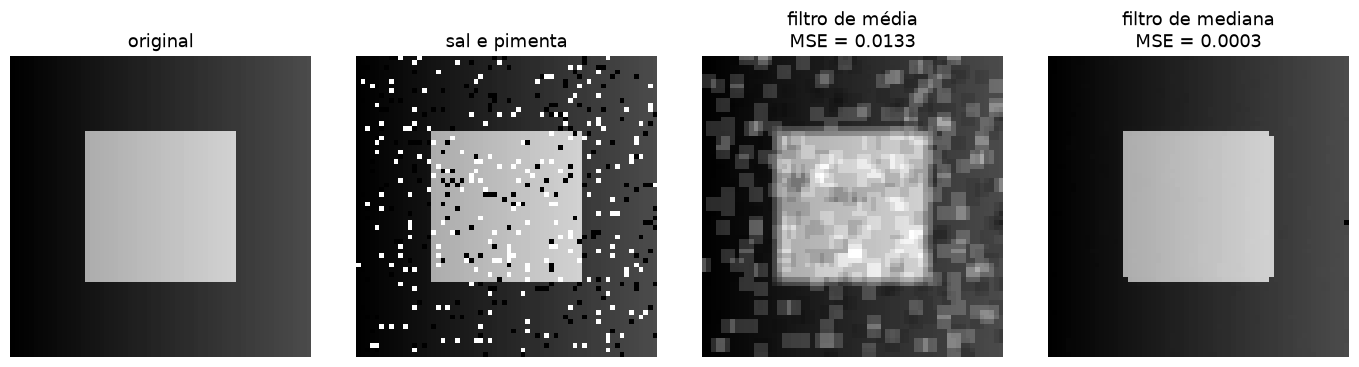

In [35]:
from scipy.ndimage import median_filter, uniform_filter

g = np.random.default_rng(5)
yy, xx = np.mgrid[:64, :64]
limpa = 0.3 * xx / 64                      # fundo em degradê
limpa[16:48, 16:48] += 0.6                 # quadrado claro
ruidosa = limpa.copy()
sorteio = g.random(limpa.shape)
ruidosa[sorteio < 0.05] = 0.0              # 5% de pixels pretos (pimenta)
ruidosa[sorteio > 0.95] = 1.5              # 5% de pixels estourados (sal)

img_media   = uniform_filter(ruidosa, size=3)
img_mediana = median_filter(ruidosa, size=3)
mse_img = lambda a: np.mean((a - limpa) ** 2)
assert mse_img(img_mediana) < mse_img(img_media)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (titulo, im) in zip(axs, [
        ("original", limpa), ("sal e pimenta", ruidosa),
        (f"filtro de média\nMSE = {mse_img(img_media):.4f}", img_media),
        (f"filtro de mediana\nMSE = {mse_img(img_mediana):.4f}", img_mediana)]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(titulo); ax.axis("off")
plt.tight_layout(); plt.show()

### 9.5 · Engenharia e Indústria: MTTR

🏭 No trabalho (manutenção). O MTTR (Mean Time To Repair) costuma ser reportado como média, mas os tempos de reparo têm cauda longa: a maioria é rápida e alguns poucos são longos (uma peça importada, um fim de semana sem equipe).

In [36]:
mttr = rng.lognormal(mean=1.0, sigma=0.7, size=120)      # horas
mttr[:3] = [200, 350, 500]                               # três paradas longas

print(f"MTTR médio = {mttr.mean():.1f} h")
print(f"MTTR mediano = {np.median(mttr):.1f} h")
print(f"{(mttr < mttr.mean()).mean():.0%} dos reparos levam menos que o MTTR médio")

MTTR médio = 12.0 h
MTTR mediano = 2.6 h
97% dos reparos levam menos que o MTTR médio


A média reflete o custo total (útil para orçamento), e a mediana reflete o reparo típico (útil para dimensionar a equipe). Reporte as duas. Para limpar a telemetria dos sensores com a mediana, veja o mini-caso a seguir.

---

## 10 · Mini-caso: limpando a telemetria de um motor

**Contexto.** Um sensor mede a temperatura (°C) de um motor industrial, uma etapa de qualquer pipeline de manutenção preditiva. O sinal verdadeiro tem uma oscilação lenta e um degrau (o motor passou a operar com mais carga). Só que o sensor gera picos espúrios (falhas de leitura de $\pm10$ a $\pm25$ °C) em cerca de 4% das amostras. Queremos recuperar o sinal sem destruir o degrau, que é a informação mais importante.

O filtro de Hampel usa a mediana e o MAD em uma janela deslizante: se um ponto se afasta da mediana local por mais de $k$ MADs, ele é um pico e é substituído pela mediana da janela:

$$\left|x_t - \tilde{x}_t\right| > k \cdot 1{,}4826 \cdot \text{MAD}_t \;\Longrightarrow\; x_t \leftarrow \tilde{x}_t$$


In [37]:
def simular_sensor(seed=11, n=600):
    g = np.random.default_rng(seed)
    t = np.arange(n)
    verdadeiro = 70 + 2 * np.sin(2 * np.pi * t / 200) + np.where(t >= 300, 8.0, 0.0)   # oscilação + degrau em t=300
    obs = verdadeiro + g.normal(0, 0.4, n)
    picos = g.random(n) < 0.04
    obs[picos] += g.choice([-1, 1], picos.sum()) * g.uniform(10, 25, picos.sum())
    return t, verdadeiro, obs, picos

def media_movel(x, w):
    return pd.Series(x).rolling(w, center=True, min_periods=1).mean().to_numpy()

def mediana_movel(x, w):
    return pd.Series(x).rolling(w, center=True, min_periods=1).median().to_numpy()

def hampel(x, w=11, k=3.0):
    meio = w // 2
    janelas = sliding_window_view(np.pad(x, meio, mode="reflect"), w)       # uma janela por ponto
    med = np.median(janelas, axis=1)
    mad = 1.4826 * np.median(np.abs(janelas - med[:, None]), axis=1)
    outlier = np.abs(x - med) > k * mad
    return np.where(outlier, med, x), outlier

t, verdadeiro, obs, picos = simular_sensor()
w = 11
limpo, marcados_h = hampel(obs, w=w, k=3.0)

sinais = {
    "bruto":                obs,
    "média móvel":          media_movel(obs, w),
    "mediana móvel":        mediana_movel(obs, w),
    "Hampel":               limpo,
    "Hampel + média móvel": media_movel(limpo, 5),
}
rmse = pd.Series({nome: np.sqrt(np.mean((s - verdadeiro) ** 2)) for nome, s in sinais.items()},
                 name="RMSE vs. sinal verdadeiro (°C)")

acertos = (marcados_h & picos).sum()
precisao, recall = acertos / marcados_h.sum(), acertos / picos.sum()
print(f"picos reais = {picos.sum()} | marcados pelo Hampel = {marcados_h.sum()} | precisão = {precisao:.1%} | recall = {recall:.1%}")

assert rmse["mediana móvel"] < rmse["média móvel"] < rmse["bruto"]
assert rmse["Hampel"] < rmse["bruto"]
assert recall > 0.9
rmse.round(3).to_frame()

picos reais = 23 | marcados pelo Hampel = 31 | precisão = 74.2% | recall = 100.0%


,RMSE vs. sinal verdadeiro (°C)
bruto,3.9220
média móvel,1.2820
mediana móvel,0.1630
Hampel,0.3720
Hampel + média móvel,0.2580


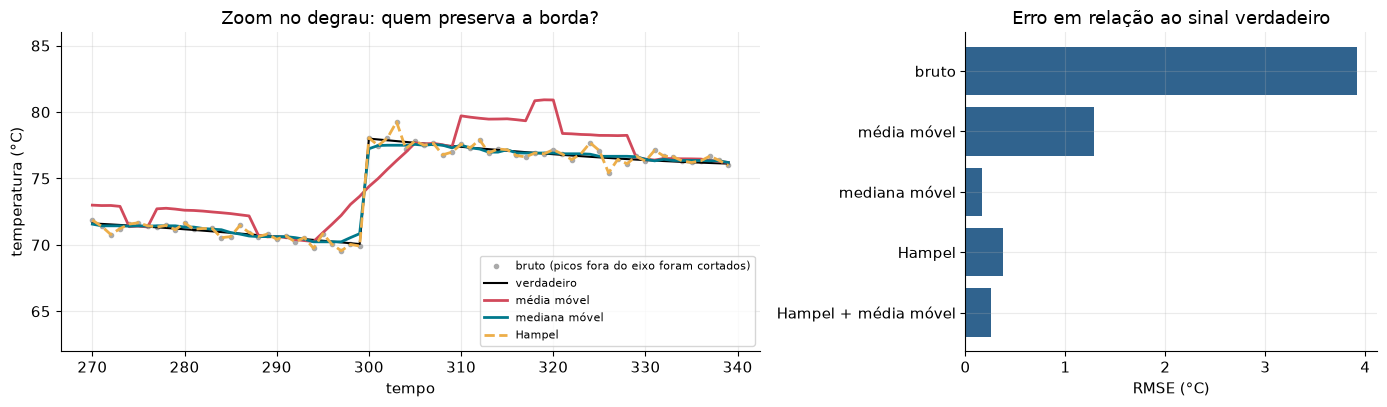

In [38]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.7, 1]})
zoom = slice(270, 340)
axs[0].plot(t[zoom], obs[zoom], ".", color="#aaaaaa", label="bruto (picos fora do eixo foram cortados)")
axs[0].plot(t[zoom], verdadeiro[zoom], color="black", lw=1.5, label="verdadeiro")
axs[0].plot(t[zoom], sinais["média móvel"][zoom], color=COR["media"], lw=2, label="média móvel")
axs[0].plot(t[zoom], sinais["mediana móvel"][zoom], color=COR["mediana"], lw=2, label="mediana móvel")
axs[0].plot(t[zoom], sinais["Hampel"][zoom], color=COR["ponderada"], lw=2, ls="--", label="Hampel")
axs[0].set_ylim(62, 86); axs[0].set_xlabel("tempo"); axs[0].set_ylabel("temperatura (°C)")
axs[0].set_title("Zoom no degrau: quem preserva a borda?"); axs[0].legend(fontsize=8, loc="lower right")

axs[1].barh(rmse.index, rmse.values, color=[COR["base"]] * len(rmse))
axs[1].set_xlabel("RMSE (°C)"); axs[1].set_title("Erro em relação ao sinal verdadeiro"); axs[1].invert_yaxis()
plt.tight_layout(); plt.show()

Três leituras do resultado:

* **A média móvel** é arrastada pelos picos e borra o degrau (a borda vira uma rampa). **A mediana móvel** mantém a borda nítida, porque um valor extremo na janela não a desloca.
* **O Hampel** só troca os pontos marcados como pico e deixa os demais exatamente como foram medidos. Além de limpar, ele entrega uma lista de anomalias com precisão e revocação mensuráveis, útil para gerar alertas.
* **O RMSE não é o único critério:** a mediana móvel suaviza tudo (inclusive o ruído bom), e o Hampel preserva o detalhe. Na prática, combinam-se os dois: Hampel para tirar os picos e uma média móvel curta para suavizar.

Como o resultado depende do tamanho da janela, veja a sensibilidade:

In [39]:
janelas = [5, 11, 21, 41]
def erro(s): return np.sqrt(np.mean((s - verdadeiro) ** 2))

sensibilidade = pd.DataFrame({
    "média móvel": [erro(media_movel(obs, j)) for j in janelas],
    "mediana móvel": [erro(mediana_movel(obs, j)) for j in janelas],
    "Hampel": [erro(hampel(obs, w=j)[0]) for j in janelas],
}, index=pd.Index(janelas, name="janela"))
sensibilidade.round(3)

,média móvel,mediana móvel,Hampel
janela,,,
5,1.7970,0.2280,0.3670
11,1.2820,0.1630,0.3720
21,0.9620,0.1620,0.3740
41,0.7960,0.3640,0.3760


Neste experimento: na média móvel, janelas maiores diluem melhor os picos (o erro cai), mas à custa de borrar mais as mudanças reais. Na mediana móvel existe uma faixa boa de janela (11 a 21), e além dela o erro sobe, porque a janela passa a suavizar a própria dinâmica do sinal. O Hampel quase não depende da janela, porque só mexe nos pontos marcados. Escolher w e k é um ajuste que se faz com dados de validação rotulados, e não "a olho".

---

## 11 · Resumo e ponte

### 🧾 Cheat-sheet

| | Mediana |
| :--- | :--- |
| **Definição** | Valor central da amostra ordenada (média dos dois centrais se n par) |
| **NumPy / Pandas** | `np.median(x)` · `s.median()` · `np.nanmedian(x)` com ausentes |
| **Minimiza** | \(\sum \lvert x_i - c\rvert\) (erro absoluto) |
| **Ponto de ruptura** | 50% |
| **Eficiência na Normal** | ≈ 64% (a média tem 100%) |
| **Diagnóstico de assimetria** | Média - mediana (>0: cauda à direita) |
| **Use quando** | Assimetria, outliers, ordinais, "valor típico" |
| **Cuidado** | Não é aditiva · mediana de medianas · NaN · cega às caudas |

---

### 🔑 As 7 ideias para levar

* A mediana é o valor do meio e só depende da ordem: cada observação vale um voto.
* Ela minimiza o erro absoluto, como a média minimiza o quadrático.
* Seu ponto de ruptura é 50%, o da média é 0%.
* Média - mediana é um termômetro de assimetria.
* Robustez tem preço: com dados limpos a mediana é menos eficiente (≈ 64%).
* Não é aditiva e a mediana geral não sai das medianas dos grupos.
* É a base de filtros robustos (Hampel), MAD, regressão por mediana e escalonamento robusto.

---

### 📚 Referências

* BUSSAB, W. O.; MORETTIN, P. A. **Estatística Básica**. Saraiva.
* MORETTIN, P. A.; SINGER, J. M. **Estatística e Ciência de Dados**. LTC.
* HUBER, P. J.; RONCHETTI, E. M. **Robust Statistics**. Wiley.
* Documentação: `numpy.median` · `pandas.Series.median` · `scipy.ndimage.median_filter`
